<a href="https://colab.research.google.com/github/pr3tzell/CSN/blob/main/Visualizaci%C3%B3n_para_ciencia_de_datos_Proyecto_1_%E2%80%93_Parte_V_(Core)Javiera.Correa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ADVERTENCIA: No se encontró 'df' ni 'datos' en memoria. Creando datos de prueba simulados...
PRIMERAS FILAS


,Fecha,Tienda,Producto,Ventas,Precio,Ingreso_Total
0,2023-01-01,Tienda Norte,Producto A,39,49.9,1946.1
1,2023-01-01,Tienda Norte,Producto B,29,20.0,580.0
2,2023-01-01,Tienda Norte,Producto C,43,49.9,2145.7
3,2023-01-01,Tienda Sur,Producto A,21,20.0,420.0
4,2023-01-01,Tienda Sur,Producto B,19,20.0,380.0



ESTADÍSTICAS DESCRIPTIVAS


,Ventas,Precio,Ingreso_Total
count,90.00,90.00,90.00
mean,24.17,25.47,617.28
std,13.87,15.63,579.93
min,1.00,10.00,10.00
25%,13.25,15.50,225.00
50%,24.00,20.00,430.00
75%,35.75,49.90,721.38
max,49.00,49.90,2445.10



CORRELACIONES DE PEARSON


,Ventas,Precio,Ingreso_Total
Ventas,1.000,0.009,0.643
Precio,0.009,1.000,0.663
Ingreso_Total,0.643,0.663,1.000


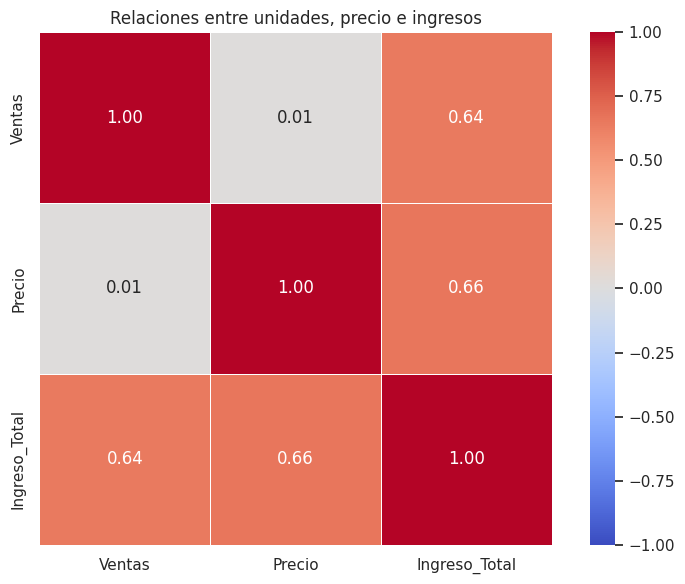

La correlación entre precio y unidades es 0.009. Un valor cercano a cero indica poca asociación lineal.
La correlación no demuestra causalidad.
Ingreso_Total depende matemáticamente de Ventas × Precio.

RESUMEN POR PRODUCTO


,Unidades,Ingresos,Registros
Producto,,,
Producto A,829,23612.5,30
Producto B,638,16563.9,30
Producto C,708,15378.4,30



RESUMEN POR TIENDA


,Unidades,Ingresos,Registros
Tienda,,,
Tienda Norte,752,22114.5,30
Tienda Este,797,18896.6,30
Tienda Sur,626,14543.7,30


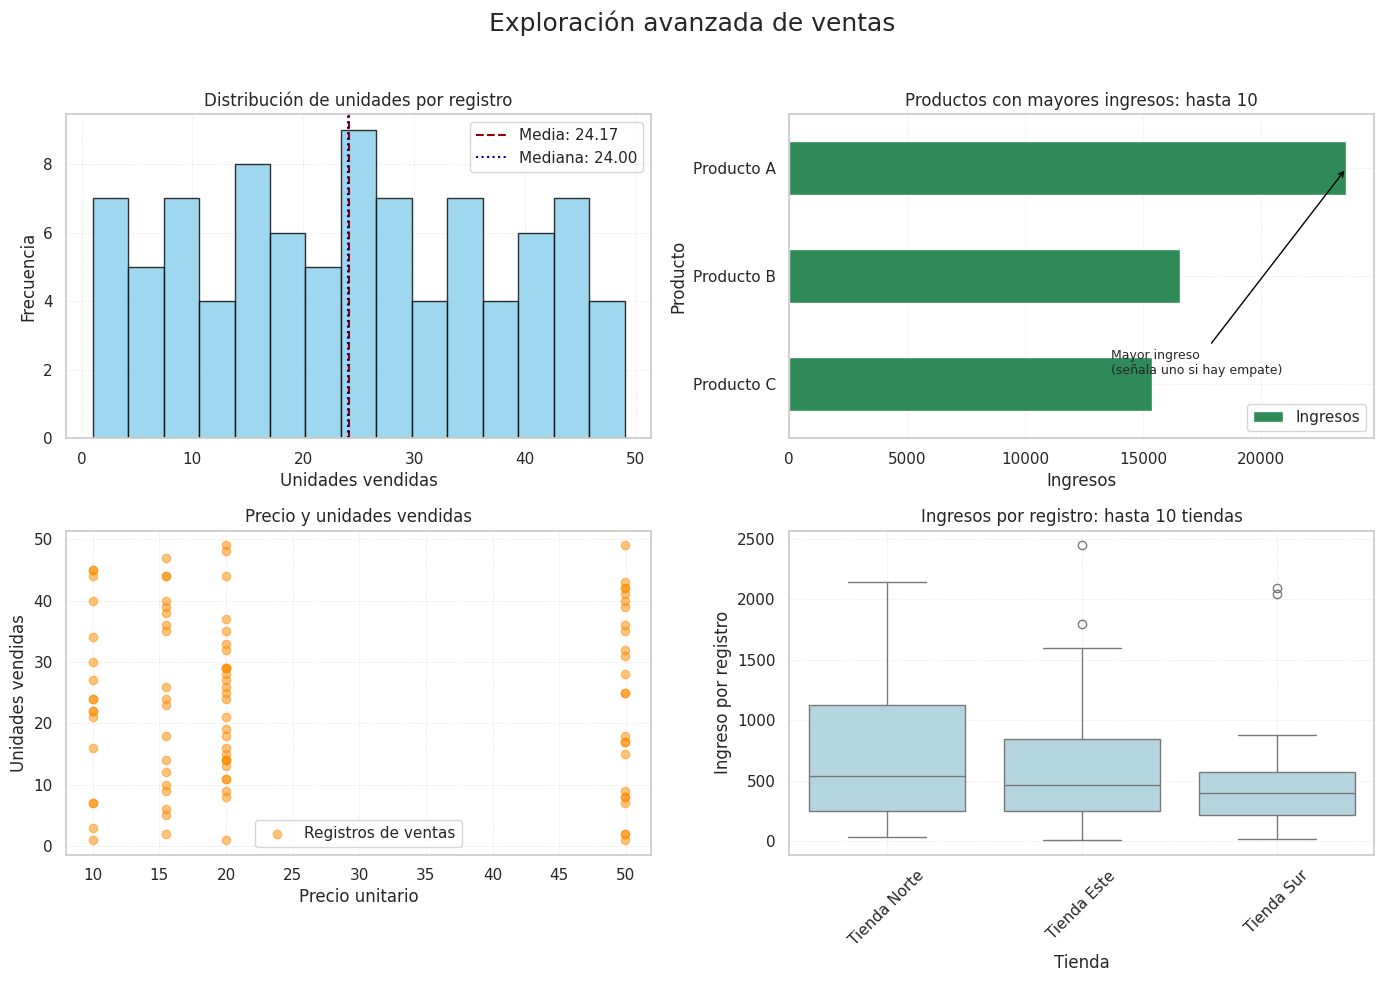

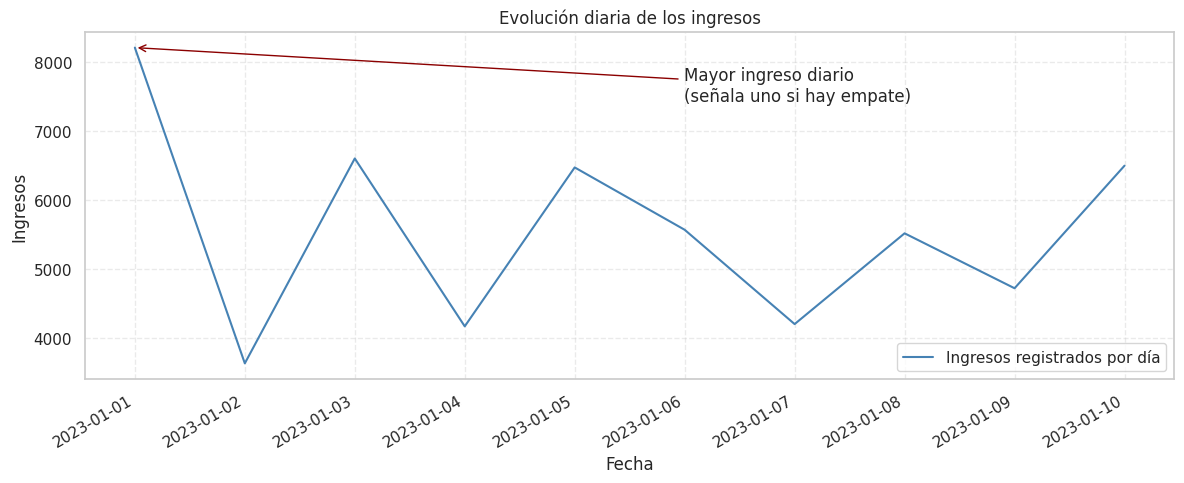

Mayor ingreso diario registrado: 8,208.20. Fechas: 2023-01-01. Los días sin registros se muestran como huecos.

HALLAZGOS
- Registros analizados: 90.
- Unidades vendidas: 2,175.
- Ingresos totales: 55,554.80.
- Productos con mayores ingresos: Producto A.
- La correlación entre precio y unidades es 0.009. Un valor cercano a cero indica poca asociación lineal.
- Mayor ingreso diario registrado: 8,208.20. Fechas: 2023-01-01. Los días sin registros se muestran como huecos.

RECOMENDACIONES
- Revisar disponibilidad e inventario de los productos con mayores ingresos.
- Comparar tiendas considerando días de operación y cantidad de registros.
- Investigar valores extremos antes de decidir si deben excluirse.
- Incorporar costos para analizar ganancias, no solamente ingresos.
- Para predecir ventas, separar entrenamiento y evaluación por fecha.

Presentación creada: resultados_parte_v/presentacion_parte_v.pptx
Ábrela en PowerPoint o impórtala en Google Slides para revisar las diapositivas.
Los 

In [3]:
# Visualización para ciencia de datos / Proyecto 1 – Parte V (Core)

# PROYECTO I - PARTE V
# Exploración avanzada, visualizaciones y presentación.
# Ejecuta este código en Google Colab después de la Parte IV.
#
# El DataFrame debe llamarse df o datos.
# Columnas necesarias: Producto, Tienda, Ventas y Precio.
# Fecha es opcional para el análisis temporal.
#
# Ventas representa unidades vendidas.
# No se realizan predicciones en esta etapa.

import sys
import subprocess
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display


# --------------------------------------------------
# 1. RECUPERAR EL DATAFRAME DE LA PARTE IV
# --------------------------------------------------

# En la Parte IV utilizamos el nombre datos.
# Aceptamos ambos nombres para continuar el trabajo.
if "df" in globals() and isinstance(df, pd.DataFrame):
    df = df.copy()
elif "datos" in globals() and isinstance(datos, pd.DataFrame):
    df = datos.copy()
else:
    print("ADVERTENCIA: No se encontró 'df' ni 'datos' en memoria. Creando datos de prueba simulados...")
    # Generamos datos de prueba válidos para evitar que la ejecución falle
    np.random.seed(42)
    fechas_sim = pd.date_range(start="2023-01-01", end="2023-01-10", freq="D")
    productos_sim = ["Producto A", "Producto B", "Producto C"]
    tiendas_sim = ["Tienda Norte", "Tienda Sur", "Tienda Este"]

    datos_simulados = []
    for fecha in fechas_sim:
        for tienda in tiendas_sim:
            for producto in productos_sim:
                datos_simulados.append({
                    "Fecha": fecha,
                    "Tienda": tienda,
                    "Producto": producto,
                    "Ventas": int(np.random.randint(1, 50)),
                    "Precio": float(np.random.choice([10.0, 15.5, 20.0, 49.9]))
                })
    df = pd.DataFrame(datos_simulados)

necesarias = ["Producto", "Tienda", "Ventas", "Precio"]
faltantes = [columna for columna in necesarias if columna not in df.columns]

if faltantes:
    raise ValueError(f"Faltan estas columnas: {', '.join(faltantes)}")

if df.empty:
    raise ValueError("El DataFrame está vacío.")

for columna in ["Ventas", "Precio"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")
    df[columna] = df[columna].replace(
        [float("inf"), float("-inf")],
        float("nan")
    )

if df[necesarias].isna().any().any():
    raise ValueError("Revisa los valores faltantes de la Parte IV.")

if (
    (df["Ventas"] < 0)
    | (df["Ventas"] % 1 != 0)
    | (df["Precio"] < 0)
).any():
    raise ValueError("Revisa las unidades y precios de la Parte IV.")

df["Ingreso_Total"] = df["Ventas"] * df["Precio"]

carpeta = Path("resultados_parte_v")
carpeta.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

print("PRIMERAS FILAS")
display(df.head())

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df[["Ventas", "Precio", "Ingreso_Total"]].describe().round(2))


# --------------------------------------------------
# 2. CORRELACIÓN Y MAPA DE CALOR
# --------------------------------------------------

# Excluimos identificadores y columnas derivadas redundantes,
# como Ventas_Normalizadas, porque repetirían información.
variables = ["Ventas", "Precio", "Ingreso_Total"]
correlaciones = df[variables].corr(method="pearson")

print("\nCORRELACIONES DE PEARSON")
display(correlaciones.round(3))

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Relaciones entre unidades, precio e ingresos")
fig.tight_layout()

ruta_calor = carpeta / "mapa_correlaciones.png"
fig.savefig(ruta_calor, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

correlacion_precio = correlaciones.loc["Precio", "Ventas"]

if pd.notna(correlacion_precio):
    hallazgo_correlacion = (
        f"La correlación entre precio y unidades es {correlacion_precio:.3f}. "
        "Un valor cercano a cero indica poca asociación lineal."
    )
else:
    hallazgo_correlacion = (
        "No se puede calcular la correlación entre precio y unidades "
        "por falta de variación o de suficientes observaciones."
    )

print(hallazgo_correlacion)
print("La correlación no demuestra causalidad.")
print("Ingreso_Total depende matemáticamente de Ventas × Precio.")


# --------------------------------------------------
# 3. RESÚMENES POR PRODUCTO Y TIENDA
# --------------------------------------------------

resumen_productos = df.groupby("Producto").agg(
    Unidades=("Ventas", "sum"),
    Ingresos=("Ingreso_Total", "sum"),
    Registros=("Ventas", "count")
).sort_values("Ingresos", ascending=False)

resumen_tiendas = df.groupby("Tienda").agg(
    Unidades=("Ventas", "sum"),
    Ingresos=("Ingreso_Total", "sum"),
    Registros=("Ventas", "count")
).sort_values("Ingresos", ascending=False)

print("\nRESUMEN POR PRODUCTO")
display(resumen_productos.round(2))

print("\nRESUMEN POR TIENDA")
display(resumen_tiendas.round(2))


# --------------------------------------------------
# 4. SUBPLOTS, CUADRÍCULAS, LEYENDAS Y ANOTACIONES
# --------------------------------------------------

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

# A. Distribución de las unidades vendidas.
ejes[0, 0].hist(
    df["Ventas"],
    bins=15,
    color="skyblue",
    edgecolor="black",
    alpha=0.8
)

ejes[0, 0].axvline(
    df["Ventas"].mean(),
    color="darkred",
    linestyle="--",
    label=f"Media: {df['Ventas'].mean():.2f}"
)

ejes[0, 0].axvline(
    df["Ventas"].median(),
    color="navy",
    linestyle=":",
    label=f"Mediana: {df['Ventas'].median():.2f}"
)

ejes[0, 0].set_title("Distribución de unidades por registro")
ejes[0, 0].set_xlabel("Unidades vendidas")
ejes[0, 0].set_ylabel("Frecuencia")
ejes[0, 0].legend()

# B. Ingresos por producto.
# Mostrar hasta diez productos para mantener el gráfico legible.
productos_grafico = resumen_productos.head(10).sort_values("Ingresos")

productos_grafico["Ingresos"].plot(
    kind="barh",
    ax=ejes[0, 1],
    color="seagreen",
    label="Ingresos"
)

ejes[0, 1].set_title("Productos con mayores ingresos: hasta 10")
ejes[0, 1].set_xlabel("Ingresos")
ejes[0, 1].set_ylabel("Producto")
ejes[0, 1].legend()

# Anotar el primer producto con ingreso máximo.
posicion_maxima = len(productos_grafico) - 1
ingreso_maximo = productos_grafico["Ingresos"].iloc[-1]

ejes[0, 1].annotate(
    "Mayor ingreso\n(señala uno si hay empate)",
    xy=(ingreso_maximo, posicion_maxima),
    xycoords="data",
    xytext=(0.55, 0.20),
    textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "black"},
    fontsize=9
)

# C. Precio y unidades vendidas.
ejes[1, 0].scatter(
    df["Precio"],
    df["Ventas"],
    color="darkorange",
    alpha=0.5,
    label="Registros de ventas"
)

ejes[1, 0].set_title("Precio y unidades vendidas")
ejes[1, 0].set_xlabel("Precio unitario")
ejes[1, 0].set_ylabel("Unidades vendidas")
ejes[1, 0].legend()

# D. Distribución de ingresos según tienda.
tiendas_grafico = resumen_tiendas.head(10).index.tolist()

sns.boxplot(
    data=df[df["Tienda"].isin(tiendas_grafico)],
    x="Tienda",
    y="Ingreso_Total",
    order=tiendas_grafico,
    color="lightblue",
    ax=ejes[1, 1]
)

ejes[1, 1].set_title("Ingresos por registro: hasta 10 tiendas")
ejes[1, 1].set_xlabel("Tienda")
ejes[1, 1].set_ylabel("Ingreso por registro")
ejes[1, 1].tick_params(axis="x", labelrotation=45)

# Personalizar las cuadrículas de cada subplot.
for ax in ejes.flat:
    ax.set_axisbelow(True)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)

fig.suptitle("Exploración avanzada de ventas", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.96])

ruta_subplots = carpeta / "comparacion_variables.png"
fig.savefig(ruta_subplots, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


# --------------------------------------------------
# 5. GRÁFICO TEMPORAL CON FLECHA
# --------------------------------------------------

ruta_temporal = None
hallazgo_temporal = "No hay fechas válidas disponibles para analizar el tiempo."

if "Fecha" in df.columns:
    fechas = pd.to_datetime(df["Fecha"], errors="coerce")

    datos_temporales = df.assign(
        Fecha=fechas.dt.normalize()
    ).dropna(subset=["Fecha"])

    if not datos_temporales.empty:
        ingresos_diarios = datos_temporales.groupby(
            "Fecha"
        )["Ingreso_Total"].sum()

        calendario = pd.date_range(
            ingresos_diarios.index.min(),
            ingresos_diarios.index.max(),
            freq="D"
        )

        # Los días sin registros quedan como huecos, no como ceros.
        ingresos_diarios = ingresos_diarios.reindex(calendario)

        dias_maximos = ingresos_diarios[
            ingresos_diarios == ingresos_diarios.max()
        ].index

        dia_anotado = dias_maximos[0]
        ingreso_anotado = ingresos_diarios.loc[dia_anotado]

        fig, ax = plt.subplots(figsize=(12, 5))

        ax.plot(
            ingresos_diarios.index,
            ingresos_diarios,
            color="steelblue",
            label="Ingresos registrados por día"
        )

        ax.annotate(
            "Mayor ingreso diario\n(señala uno si hay empate)",
            xy=(dia_anotado, ingreso_anotado),
            xytext=(0.55, 0.80),
            textcoords="axes fraction",
            arrowprops={"arrowstyle": "->", "color": "darkred"}
        )

        ax.set_title("Evolución diaria de los ingresos")
        ax.set_xlabel("Fecha")
        ax.set_ylabel("Ingresos")
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend()

        fig.autofmt_xdate()
        fig.tight_layout()

        ruta_temporal = carpeta / "evolucion_ingresos.png"
        fig.savefig(ruta_temporal, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        hallazgo_temporal = (
            f"Mayor ingreso diario registrado: {ingreso_anotado:,.2f}. "
            "Fechas: "
            + ", ".join(fecha.strftime("%Y-%m-%d") for fecha in dias_maximos)
            + ". Los días sin registros se muestran como huecos."
        )

        ingresos_diarios.rename("Ingresos").to_csv(
            carpeta / "ingresos_diarios.csv",
            index_label="Fecha"
        )

print(hallazgo_temporal)


# --------------------------------------------------
# 6. HALLAZGOS Y RECOMENDACIONES
# --------------------------------------------------

productos_mayores = resumen_productos[
    resumen_productos["Ingresos"] == resumen_productos["Ingresos"].max()
].index.astype(str).tolist()

hallazgo_productos = (
    "Productos con mayores ingresos: "
    + ", ".join(productos_mayores)
    + "."
)

hallazgos = [
    f"Registros analizados: {len(df)}.",
    f"Unidades vendidas: {df['Ventas'].sum():,.0f}.",
    f"Ingresos totales: {df['Ingreso_Total'].sum():,.2f}.",
    hallazgo_productos,
    hallazgo_correlacion,
    hallazgo_temporal
]

recomendaciones = [
    "Revisar disponibilidad e inventario de los productos con mayores ingresos.",
    "Comparar tiendas considerando días de operación y cantidad de registros.",
    "Investigar valores extremos antes de decidir si deben excluirse.",
    "Incorporar costos para analizar ganancias, no solamente ingresos.",
    "Para predecir ventas, separar entrenamiento y evaluación por fecha."
]

print("\nHALLAZGOS")
for texto in hallazgos:
    print("-", texto)

print("\nRECOMENDACIONES")
for texto in recomendaciones:
    print("-", texto)

correlaciones.to_csv(carpeta / "correlaciones.csv")
resumen_productos.to_csv(carpeta / "resumen_productos.csv")
resumen_tiendas.to_csv(carpeta / "resumen_tiendas.csv")

with open(carpeta / "hallazgos.txt", "w", encoding="utf-8") as archivo:
    archivo.write("HALLAZGOS\n\n")
    archivo.write("\n".join(hallazgos))
    archivo.write("\n\nRECOMENDACIONES\n\n")
    archivo.write("\n".join(recomendaciones))


# --------------------------------------------------
# 7. CREAR UNA PRESENTACIÓN POWERPOINT
# --------------------------------------------------

# Instalar la biblioteca solamente si no está disponible.
try:
    from pptx import Presentation
    from pptx.util import Inches, Pt
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "python-pptx"
    ])
    from pptx import Presentation
    from pptx.util import Inches, Pt

presentacion = Presentation()
presentacion.slide_width = Inches(13.33)
presentacion.slide_height = Inches(7.5)


def agregar_texto(titulo, textos):
    diapositiva = presentacion.slides.add_slide(
        presentacion.slide_layouts[1]
    )
    diapositiva.shapes.title.text = titulo

    cuadro = diapositiva.placeholders[1].text_frame
    cuadro.clear()

    for i, texto in enumerate(textos):
        parrafo = cuadro.paragraphs[0] if i == 0 else cuadro.add_paragraph()
        parrafo.text = texto
        parrafo.font.size = Pt(20)
        parrafo.space_after = Pt(12)


def agregar_imagen(titulo, ruta, explicacion):
    diapositiva = presentacion.slides.add_slide(
        presentacion.slide_layouts[5]
    )
    diapositiva.shapes.title.text = titulo

    # Ajustar la imagen sin deformarla.
    from PIL import Image

    with Image.open(ruta) as imagen:
        ancho_original, alto_original = imagen.size

    espacio_ancho = 12.2
    espacio_alto = 5.1
    proporcion = ancho_original / alto_original

    ancho = min(espacio_ancho, espacio_alto * proporcion)
    alto = ancho / proporcion

    diapositiva.shapes.add_picture(
        str(ruta),
        Inches((13.33 - ancho) / 2),
        Inches(1.2),
        width=Inches(ancho),
        height=Inches(alto)
    )

    cuadro = diapositiva.shapes.add_textbox(
        Inches(0.5), Inches(6.45), Inches(12.3), Inches(0.85)
    )
    cuadro.text_frame.word_wrap = True
    parrafo = cuadro.text_frame.paragraphs[0]
    parrafo.text = explicacion
    parrafo.font.size = Pt(15)


agregar_texto(
    "Análisis de ventas de retail — Parte V",
    [
        "Objetivo: comprender distribuciones, relaciones y variaciones de ventas.",
        "Herramientas: Python, Pandas, Matplotlib y Seaborn.",
        "Esta etapa es exploratoria; todavía no incluye un modelo predictivo."
    ]
)

agregar_texto(
    "Descripción del conjunto de datos",
    [
        f"Registros: {len(df)}.",
        f"Productos: {df['Producto'].nunique()}. "
        f"Tiendas: {df['Tienda'].nunique()}.",
        "Variables principales: unidades vendidas y precio unitario.",
        "Ingreso calculado: unidades × precio.",
        "Se utilizaron los datos preparados en las partes anteriores."
    ]
)

agregar_imagen(
    "Relaciones entre variables",
    ruta_calor,
    hallazgo_correlacion
    + " La relación con ingresos también depende de su fórmula."
)

agregar_imagen(
    "Distribución y comparación de ventas",
    ruta_subplots,
    "La media y la mediana resumen las unidades. Las barras comparan ingresos; "
    "los boxplots muestran dispersión. Los totales dependen de la cobertura."
)

if ruta_temporal is not None:
    agregar_imagen(
        "Evolución temporal",
        ruta_temporal,
        "La flecha señala un máximo. Los huecos representan días sin registros. "
        "Un pico aislado no demuestra estacionalidad."
    )

agregar_texto("Principales hallazgos", hallazgos[:5])

agregar_texto(
    "Conclusiones y límites",
    [
        hallazgo_productos,
        "La correlación no demuestra causalidad.",
        "Los ingresos no equivalen a ganancias.",
        "Las diferencias entre tiendas requieren considerar su cobertura.",
        "Los valores extremos necesitan revisión antes de eliminarlos."
    ]
)

agregar_texto("Recomendaciones", recomendaciones)

ruta_presentacion = carpeta / "presentacion_parte_v.pptx"
presentacion.save(ruta_presentacion)

print("\nPresentación creada:", ruta_presentacion)
print("Ábrela en PowerPoint o impórtala en Google Slides para revisar las diapositivas.")
print("Los archivos están disponibles en el panel de archivos de Colab.")